# Supplementary Fig. S14: Representation of the neural value signal across different trial periods

[AI generated summary] Panel b: the analysis of Fig. 5e repeated with the neural value averaged over six time windows (panel a, a schematic, is not reproduced). Windows (`TIMES_OF_INTEREST` of `run_neural_value_across_target.py`; normalized trial time, 0 = trial start, lever touch at 1 s, target touch at 2.5 s, feedback at 3.5 s; negative times = previous trial): w1 = `after_fb` (−4 to −2 s), w2 = `it1` (−2 to 0 s), w3 = `it2` (−0.5 to 1.5 s), w4 = `before_fb` (1.5 to 3.5 s, the window of Fig. 5), w5 = `tt_centered` (2 to 3 s), w6 = `tt_centered_short` (2.25 to 2.75 s). For each window: percentage of sessions supporting the standard RL (red), inferential RL (orange) or foraging (blue) hypothesis, or none of them (grey), per area, among the sessions with a delta-rule consistent within-target value update in that window (n per area). Same code as Fig. 5e (`fig5cde_across_target.ipynb`).

**Note:** the provided results of w2 and w3 were computed with a version of the script that did not include the previous trial in the trial dataset (`n_extra_trials=(0, 0)`), so that only times from 0 s on were available: w2 contains the single time bin at 0 s and w3 the bins from 0 to 1.5 s. The current script (`n_extra_trials=(-1, 0)`) computes the full windows, so its results for w2 and w3 differ from the provided ones; for the other windows it reproduces them.

**How to run:** run all cells. Figures are saved in `figs/figS14/`.

**Results:** precomputed results are provided in `results/population_decoding/across_target_<window>` (see the README). To recompute them, run in this folder: `python run_neural_value_across_target.py` (all six windows, one after the other; each window takes several hours on a server, see the README).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
##% title Imports
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

from helpers import get_data, merge_alter_values, make_session_summary, get_session_mean_value, extract_hypothesis
import popy.config as cfg
from popy.config import COLORS as COLORS
from popy.config import RESULTS_PATH

plt.rcParams.update({'font.size': 8})

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

In [3]:
def print_stats_both(stats_summary, printres=True, ax=None, title=None): 
    # Create horizontal bar plot showing proportions for each subregion
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(1.2, 1.5))
    else:
        fig = ax.figure
    plt.rcParams.update({'font.size': 8})
    
    subregions = ['MCC', 'dLPFC', 'vLPFC'][::-1]
    ordered_hypotheses = ['Standard RL', 'Inferential RL', 'Foraging', 'none']
    all_hypotheses = stats_summary['hypothesis'].unique()
    ordered_hypotheses = ordered_hypotheses + [h for h in all_hypotheses if h not in ordered_hypotheses]
    ordered_hypotheses = ordered_hypotheses[::-1]  # Reverse order for plotting
    

    #hypotheses_all = stats_summary['hypothesis'].unique()
    #ordered_hypotheses = [h for h in ordered_hypotheses if h in hypotheses_all]  # Keep only hypotheses that are present in the data
    
    # Calculate proportions and plot bars with slight overlap
    bar_height = 0.23  # Height of each individual bar
    overlap_offset = 0.15  # How much each bar is offset (smaller = more overlap)
    subregion_spacing = 1.0  # Space between subregion groups
    subregion_totals = {}
    
    for s, subregion in enumerate(subregions):
        subregion_data = stats_summary[stats_summary['subregion'] == subregion]
        hypothesis_counts = {hypothesis: subregion_data[subregion_data['hypothesis'] == hypothesis]['count'].sum()
                             for hypothesis in ordered_hypotheses}
        total_sessions = subregion_data['count'].sum()
        subregion_totals[subregion] = int(total_sessions)
        
        # Calculate the center position for this subregion group
        base_y = s * subregion_spacing
        
        for h, hypothesis in enumerate(ordered_hypotheses):
            if hypothesis in hypothesis_counts:
                proportion = hypothesis_counts[hypothesis] / total_sessions
            else:
                proportion = 0
                
            if printres:
                print(f'Subregion: {subregion}, Hypothesis: {hypothesis}, Proportion: {proportion * 100:.1f}% ({hypothesis_counts.get(hypothesis, 0)}/{total_sessions} sessions)')
            
            # Calculate y position with overlap
            # Start from bottom and work up, with each bar slightly offset
            y_pos = base_y - (len(ordered_hypotheses) - 1) * overlap_offset / 2 + h * overlap_offset
            
            color = COLORS.get(hypothesis, 'gray')
            if hypothesis == 'Feedback coding':
                color = 'black'

            bar = ax.barh(y_pos, 
                    proportion * 100, 
                    height=bar_height, 
                    color=color, 
                    label=hypothesis if s == 0 else "",  # Only label once for legend
                    zorder=len(ordered_hypotheses) + h,  # Higher zorder for later hypotheses
                    alpha=0.8, 
                    edgecolor='grey', 
                    linewidth=0.5)
                
            # Add dot at the end of the bar
            ax.scatter(proportion * 100, y_pos, 
                        color=color, s=20, zorder=len(ordered_hypotheses) + h + 100,
                        edgecolor='black', linewidth=0.5)

    # Customize the plot
    ax.set_yticks([s * subregion_spacing for s in range(len(subregions))])
    ytick_labels = [f'{subregion}\nn={subregion_totals.get(subregion, 0)}' for subregion in subregions]
    ax.set_yticklabels(ytick_labels, rotation=0, va='center', ha='center')
    ax.set_xlabel('Percent sessions\n(%)')
    ax.set_xlim(-5, 105)
    # xticks at 0, 50, 100
    ax.set_xticks([0, 50, 100])


    ax.grid(axis='x', linestyle='--', alpha=0.5, zorder=-1)
    
    # Remove spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    #sns.despine(ax=ax, trim=True)
    
    # Create legend - only include hypotheses that actually appear in the data
    present_hypotheses = [h for h in ordered_hypotheses if h in stats_summary['hypothesis'].values]
    legend_handles = [plt.Rectangle((0,0),1,1, 
                                  facecolor=COLORS.get(hypothesis, 'gray'), 
                                  alpha=0.8, 
                                  edgecolor='grey', 
                                  linewidth=0.5) 
                     for hypothesis in present_hypotheses]
    
    if ax is None:
        fig.legend(legend_handles[::-1], present_hypotheses[::-1], loc='center left', bbox_to_anchor=(1, 0.5))
    
    if title is not None:
        ax.set_title(title, fontsize=10)

    return fig, ax, legend_handles, present_hypotheses

---
# Supplementary Fig. S14b, Fraction of sessions per hypothesis in each time window

In [4]:
base_path = os.path.join(FIGS_PATH, 'figS14')  # figures are saved here
os.makedirs(base_path, exist_ok=True)

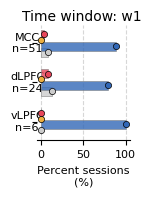

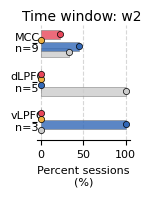

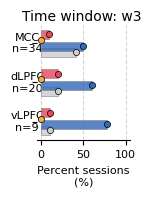

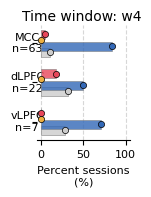

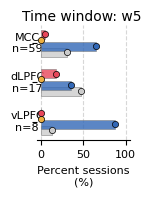

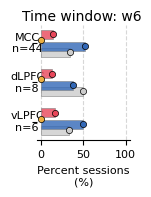

In [5]:
# run analysis across time windows
path_base = os.path.join(RESULTS_PATH, 'population_decoding')

time_windows = ['after_fb', 'it1', 'it2', 'before_fb', 'tt_centered', 'tt_centered_short']
window_labels = {'after_fb': 'w1', 'it1': 'w2', 'it2': 'w3', 'before_fb': 'w4', 'tt_centered': 'w5', 'tt_centered_short': 'w6'}  # as in Supplementary Fig. S14a
stats_all, figs_all = {}, {}  # results per time window (for the source data)
session_summary_all = []

for time_window in time_windows:
    res = get_data(os.path.join(path_base, 'across_target_' + time_window))
    res = merge_alter_values(res)  # Merge duplicate alter rows per trial
    session_summary = make_session_summary(res)
    session_summary['time_window'] = time_window
    session_summary_all.append(session_summary)

    # individual per-time-window print-stats plots
    results_df_mean = get_session_mean_value(res, session_summary)
    is_delta = results_df_mean['value_coding'].isin(['Delta rule (loose)', 'Delta rule (strict)'])
    results_df_mean_delta = results_df_mean[is_delta]
    stats_df = extract_hypothesis(results_df_mean_delta, detailed=False)
    stats_all[time_window] = stats_df

    fig_bar_both, _, _, _ = print_stats_both(stats_df, printres=False)
    fig_bar_both.suptitle(f'Time window: {window_labels[time_window]}', fontsize=10)
    figs_all[time_window] = fig_bar_both
    
    # save
    fig_bar_both.savefig(os.path.join(base_path, f'RL_forage_bars_both_{time_window}.svg'), format='svg', bbox_inches='tight', dpi=300, transparent=True)

In [6]:
# Export source data (Supplementary Figure 14b)
from popy.source_data import export_source_data

rows = []
for time_window in time_windows:
    counts = stats_all[time_window].groupby(['subregion', 'hypothesis'])['count'].sum()  # both monkeys, as in the plots
    for subregion in ['MCC', 'dLPFC', 'vLPFC']:
        n_total = int(counts.loc[subregion].sum())
        for hypothesis in ['Standard RL', 'Inferential RL', 'Foraging', 'none']:
            n = int(counts.get((subregion, hypothesis), 0))
            rows.append({'Time window': window_labels[time_window], 'Area': subregion, 'Hypothesis': 'None of the hypotheses' if hypothesis == 'none' else hypothesis,
                         'n sessions supporting the hypothesis': n, 'n sessions (total)': n_total,
                         'Percent sessions (%)': 100 * n / n_total})

export_source_data(
    'Supplementary Figure 14b',
    pd.DataFrame(rows),
    'As Fig. 5e, with the neural value averaged over each of the six time windows w1-w6 (panel a): percentage of sessions (both monkeys) '
    'supporting each hypothesis, relative to the sessions with within-target delta-rule-consistent value coding in that '
    'window (n sessions (total)). Standard RL: significant positive within-target and non-significant across-target feedback modulation of Delta V_neural; Inferential RL: significant positive within-target and significant negative across-target modulation; Foraging: significant positive modulation in both; None: all other sessions (two-sided Mann-Whitney U test over trials, rewarded vs. unrewarded, p < 0.05).',
)

Supplementary Figure 14b: source data saved (72 rows)
